# Shopper Insights ML — Complete Exploratory Data Analysis

**Dataset:** UCI Online Shoppers Purchasing Intention (ID 468)  
**Goal:** Understand data quality, class imbalance, feature distributions, relationships, and preprocessing needs before training five classifiers.  
**How to use:** Open in VS Code, select your `.venv` kernel, and run cells top-to-bottom. Place `online_shoppers_intention.csv` in `data/raw/`. This notebook does **not** train the assignment models or modify the original CSV.


## 0. Imports and dataset loading

Run from either the project root or `notebooks/` folder. Install dependencies with `python -m pip install pandas numpy matplotlib seaborn scikit-learn ipykernel`.


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)

candidates = [Path("data/raw/online_shoppers_intention.csv"), Path("../data/raw/online_shoppers_intention.csv")]
found = [p for p in candidates if p.exists()]
if not found:
    raise FileNotFoundError("Place online_shoppers_intention.csv in data/raw/ and run from the project root or notebooks/.")
DATA_PATH = found[0].resolve()
df = pd.read_csv(DATA_PATH)
print("Loaded:", DATA_PATH)
print("Shape:", df.shape)
display(df.head())

Loaded: /Users/mustak/Downloads/BITS Sem 1/Machine Learning/Assignment/Assignment 2/2026AJ05616_ML/data/raw/online_shoppers_intention.csv
Shape: (12330, 18)


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


## 1. Structure and descriptive statistics

There should be **17 predictors and 1 target (`Revenue`)**. Verify this against your own file; do not assume every downloaded copy is identical.


In [2]:
print("Column names:", df.columns.tolist())
print("\nData types and non-null counts:")
df.info()
print("\nNumerical summary:")
display(df.describe())
print("\nAll-column summary:")
display(df.describe(include="all"))
assert "Revenue" in df.columns, "Missing Revenue target column"
assert df.shape[0] >= 500 and df.shape[1] - 1 >= 12, "Dataset does not meet assignment minimums"

Column names: ['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay', 'Month', 'OperatingSystems', 'Browser', 'Region', 'TrafficType', 'VisitorType', 'Weekend', 'Revenue']

Data types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageVal

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,OperatingSystems,Browser,Region,TrafficType
count,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000
mean,2.315166,80.818611,0.503569,34.472398,31.731468,1194.746220,0.022191,0.043073,5.889258,0.061427,2.124006,2.357097,3.147364,4.069586
std,3.321784,176.779107,1.270156,140.749294,44.475503,1913.669288,0.048488,0.048597,18.568437,0.198917,0.911325,1.717277,2.401591,4.025169
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000,1.000000
25%,0.000000,0.000000,0.000000,0.000000,7.000000,184.137500,0.000000,0.014286,0.000000,0.000000,2.000000,2.000000,1.000000,2.000000
50%,1.000000,7.500000,0.000000,0.000000,18.000000,598.936905,0.003112,0.025156,0.000000,0.000000,2.000000,2.000000,3.000000,2.000000
75%,4.000000,93.256250,0.000000,0.000000,38.000000,1464.157214,0.016813,0.050000,0.000000,0.000000,3.000000,2.000000,4.000000,4.000000
max,27.000000,3398.750000,24.000000,2549.375000,705.000000,63973.522230,0.200000,0.200000,361.763742,1.000000,8.000000,13.000000,9.000000,20.000000



All-column summary:


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
count,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330,12330.000000,12330.000000,12330.000000,12330.000000,12330,12330,12330
unique,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10,NaN,NaN,NaN,NaN,3,2,2
top,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,May,NaN,NaN,NaN,NaN,Returning_Visitor,False,False
freq,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3364,NaN,NaN,NaN,NaN,10551,9462,10422
mean,2.315166,80.818611,0.503569,34.472398,31.731468,1194.746220,0.022191,0.043073,5.889258,0.061427,NaN,2.124006,2.357097,3.147364,4.069586,NaN,NaN,NaN
std,3.321784,176.779107,1.270156,140.749294,44.475503,1913.669288,0.048488,0.048597,18.568437,0.198917,NaN,0.911325,1.717277,2.401591,4.025169,NaN,NaN,NaN
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN,1.000000,1.000000,1.000000,1.000000,NaN,NaN,NaN
25%,0.000000,0.000000,0.000000,0.000000,7.000000,184.137500,0.000000,0.014286,0.000000,0.000000,NaN,2.000000,2.000000,1.000000,2.000000,NaN,NaN,NaN
50%,1.000000,7.500000,0.000000,0.000000,18.000000,598.936905,0.003112,0.025156,0.000000,0.000000,NaN,2.000000,2.000000,3.000000,2.000000,NaN,NaN,NaN
75%,4.000000,93.256250,0.000000,0.000000,38.000000,1464.157214,0.016813,0.050000,0.000000,0.000000,NaN,3.000000,2.000000,4.000000,4.000000,NaN,NaN,NaN


## 2. Missing values and duplicate analysis

`isna().sum()` counts missing entries per column. `duplicated()` flags repeated _complete rows_. `keep=False` displays all members of each repeated group. Do not delete duplicates automatically: identical feature values may represent separate sessions.


In [3]:
missing_summary = pd.DataFrame({
    "Missing Count": df.isna().sum(),
    "Missing Percentage": (100 * df.isna().mean()).round(2)
}).sort_values("Missing Count", ascending=False)
display(missing_summary)
print("Total missing cells:", int(df.isna().sum().sum()))
print("Exact duplicate rows:", int(df.duplicated().sum()))
print("Duplicate row percentage:", round(100 * df.duplicated().mean(), 2))
display(df.loc[df.duplicated(keep=False)].head(20))

,Missing Count,Missing Percentage
Administrative,0,0.0
Administrative_Duration,0,0.0
Weekend,0,0.0
VisitorType,0,0.0
TrafficType,0,0.0
Region,0,0.0
Browser,0,0.0
OperatingSystems,0,0.0
Month,0,0.0
SpecialDay,0,0.0


Total missing cells: 0
Exact duplicate rows: 125
Duplicate row percentage: 1.01


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
85,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Feb,1,1,1,3,Returning_Visitor,False,False
132,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Feb,3,2,3,3,Returning_Visitor,False,False
158,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Feb,1,1,1,3,Returning_Visitor,False,False
159,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Feb,3,2,3,3,Returning_Visitor,False,False
178,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Feb,3,2,3,3,Returning_Visitor,False,False
252,0,0.0,0,0.0,2,0.0,0.2,0.2,0.0,0.0,Mar,1,1,1,1,Returning_Visitor,False,False
286,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Mar,2,2,1,1,Returning_Visitor,False,False
293,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Mar,1,1,1,1,Returning_Visitor,True,False
298,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Mar,1,1,8,1,Returning_Visitor,False,False
330,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Mar,3,2,3,1,Returning_Visitor,False,False


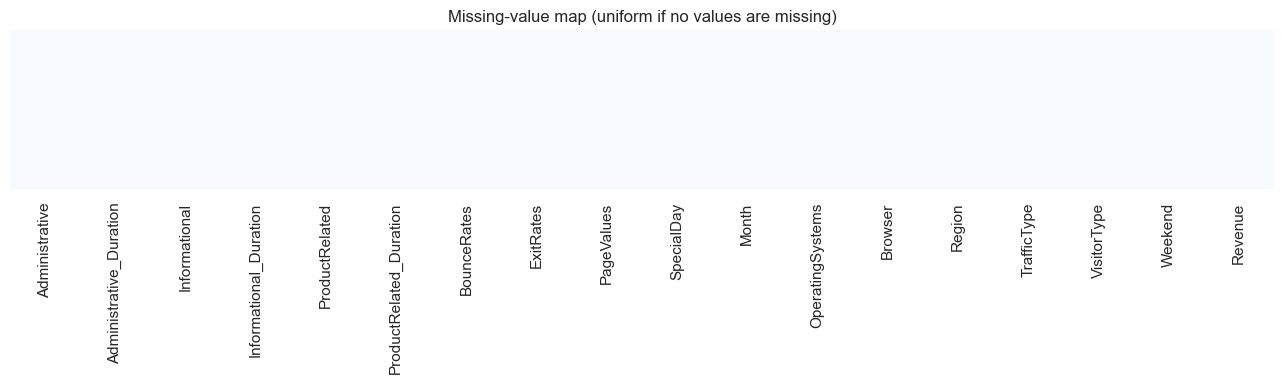

,Check,Result
0,Records,12330
1,Predictors,17
2,Missing cells,0
3,Missing targets,0
4,Exact duplicate rows,125
5,Conflicting-label feature groups,0


In [4]:
plt.figure(figsize=(13, 4))
sns.heatmap(df.isna(), cbar=False, yticklabels=False, cmap="Blues")
plt.title("Missing-value map (uniform if no values are missing)")
plt.tight_layout()
plt.show()

feature_cols = df.columns.drop("Revenue").tolist()
conflicting = df.groupby(feature_cols, dropna=False)["Revenue"].nunique(dropna=False)
conflicting_count = int((conflicting > 1).sum())
quality_report = pd.DataFrame({
    "Check": ["Records", "Predictors", "Missing cells", "Missing targets", "Exact duplicate rows", "Conflicting-label feature groups"],
    "Result": [len(df), len(feature_cols), int(df.isna().sum().sum()), int(df["Revenue"].isna().sum()), int(df.duplicated().sum()), conflicting_count]
})
display(quality_report)

## 3. Target class distribution and baseline

The original UCI data has 10,422 non-purchasing and 1,908 purchasing sessions (~84.53% vs 15.47%). **Use your computed results** if the local CSV differs. A majority-only predictor has high accuracy but zero purchase recall.


,Count,Percentage
No Purchase (0),10422,84.53
Purchase (1),1908,15.47


Majority/minority ratio: 5.46


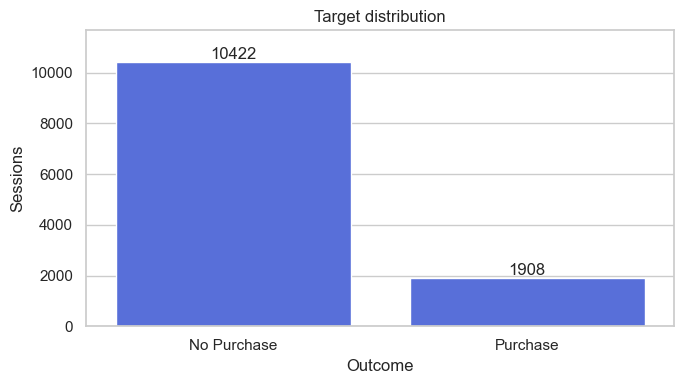

In [5]:
# Supports booleans, 0/1, and string "True"/"False" target encodings.
y = df["Revenue"].astype(str).str.strip().str.lower().map({"true": 1, "false": 0, "1": 1, "0": 0})
if y.isna().any():
    raise ValueError("Revenue has unexpected or missing labels; inspect df['Revenue'].unique()")
y = y.astype(int)
counts = y.value_counts().reindex([0, 1], fill_value=0)
class_summary = pd.DataFrame({"Count": counts, "Percentage": (counts / len(y) * 100).round(2)})
class_summary.index = ["No Purchase (0)", "Purchase (1)"]
display(class_summary)
print("Majority/minority ratio:", round(counts.max() / counts.min(), 2) if counts.min() else "Undefined")
fig, ax = plt.subplots(figsize=(7, 4))
sns.barplot(x=["No Purchase", "Purchase"], y=counts.values, color="#4361ee", ax=ax)
for i, value in enumerate(counts.values):
    ax.text(i, value + max(counts) * .01, str(value), ha="center")
ax.set(title="Target distribution", ylabel="Sessions", xlabel="Outcome", ylim=(0, max(counts)*1.12))
plt.tight_layout(); plt.show()

In [6]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, matthews_corrcoef
majority_label = int(y.mode()[0])
y_baseline = np.full(len(y), majority_label)
baseline_metrics = pd.Series({
    "Accuracy": accuracy_score(y, y_baseline),
    "Precision (purchase)": precision_score(y, y_baseline, zero_division=0),
    "Recall (purchase)": recall_score(y, y_baseline, zero_division=0),
    "F1 (purchase)": f1_score(y, y_baseline, zero_division=0),
    "MCC": matthews_corrcoef(y, y_baseline)
}, name="Majority-only baseline")
display(baseline_metrics.to_frame().round(4))
print("Note: descriptive in-sample baseline, not a held-out model evaluation.")

,Majority-only baseline
Accuracy,0.8453
Precision (purchase),0.0000
Recall (purchase),0.0000
F1 (purchase),0.0000
MCC,0.0000


Note: descriptive in-sample baseline, not a held-out model evaluation.


## 4. Univariate analysis — feature types and numerical distributions

Some integer-coded columns are **categorical**, not continuous. Treat `OperatingSystems`, `Browser`, `Region`, and `TrafficType` as categories. `SpecialDay` is numeric.


In [7]:
categorical_features = ["OperatingSystems", "Browser", "Region", "TrafficType", "VisitorType", "Month", "Weekend"]
X_eda = df.drop(columns=["Revenue", "Revenue_Label"], errors="ignore")
missing_expected = set(categorical_features) - set(X_eda.columns)
if missing_expected:
    raise ValueError(f"Expected categorical columns absent: {missing_expected}")
numerical_features = [c for c in X_eda.columns if c not in categorical_features]
print("Numerical (", len(numerical_features), "):", numerical_features)
print("Categorical (", len(categorical_features), "):", categorical_features)
assert len(numerical_features) == 10 and len(categorical_features) == 7
numeric_summary = X_eda[numerical_features].agg(["mean", "median", "std", "min", "max", "skew"]).T
numeric_summary["Unique Values"] = X_eda[numerical_features].nunique()
display(numeric_summary.round(3))

Numerical ( 10 ): ['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay']
Categorical ( 7 ): ['OperatingSystems', 'Browser', 'Region', 'TrafficType', 'VisitorType', 'Month', 'Weekend']


,mean,median,std,min,max,skew,Unique Values
Administrative,2.315,1.000,3.322,0.0,27.000,1.960,27
Administrative_Duration,80.819,7.500,176.779,0.0,3398.750,5.616,3335
Informational,0.504,0.000,1.270,0.0,24.000,4.036,17
Informational_Duration,34.472,0.000,140.749,0.0,2549.375,7.579,1258
ProductRelated,31.731,18.000,44.476,0.0,705.000,4.342,311
ProductRelated_Duration,1194.746,598.937,1913.669,0.0,63973.522,7.263,9551
BounceRates,0.022,0.003,0.048,0.0,0.200,2.948,1872
ExitRates,0.043,0.025,0.049,0.0,0.200,2.149,4777
PageValues,5.889,0.000,18.568,0.0,361.764,6.383,2704
SpecialDay,0.061,0.000,0.199,0.0,1.000,3.303,6


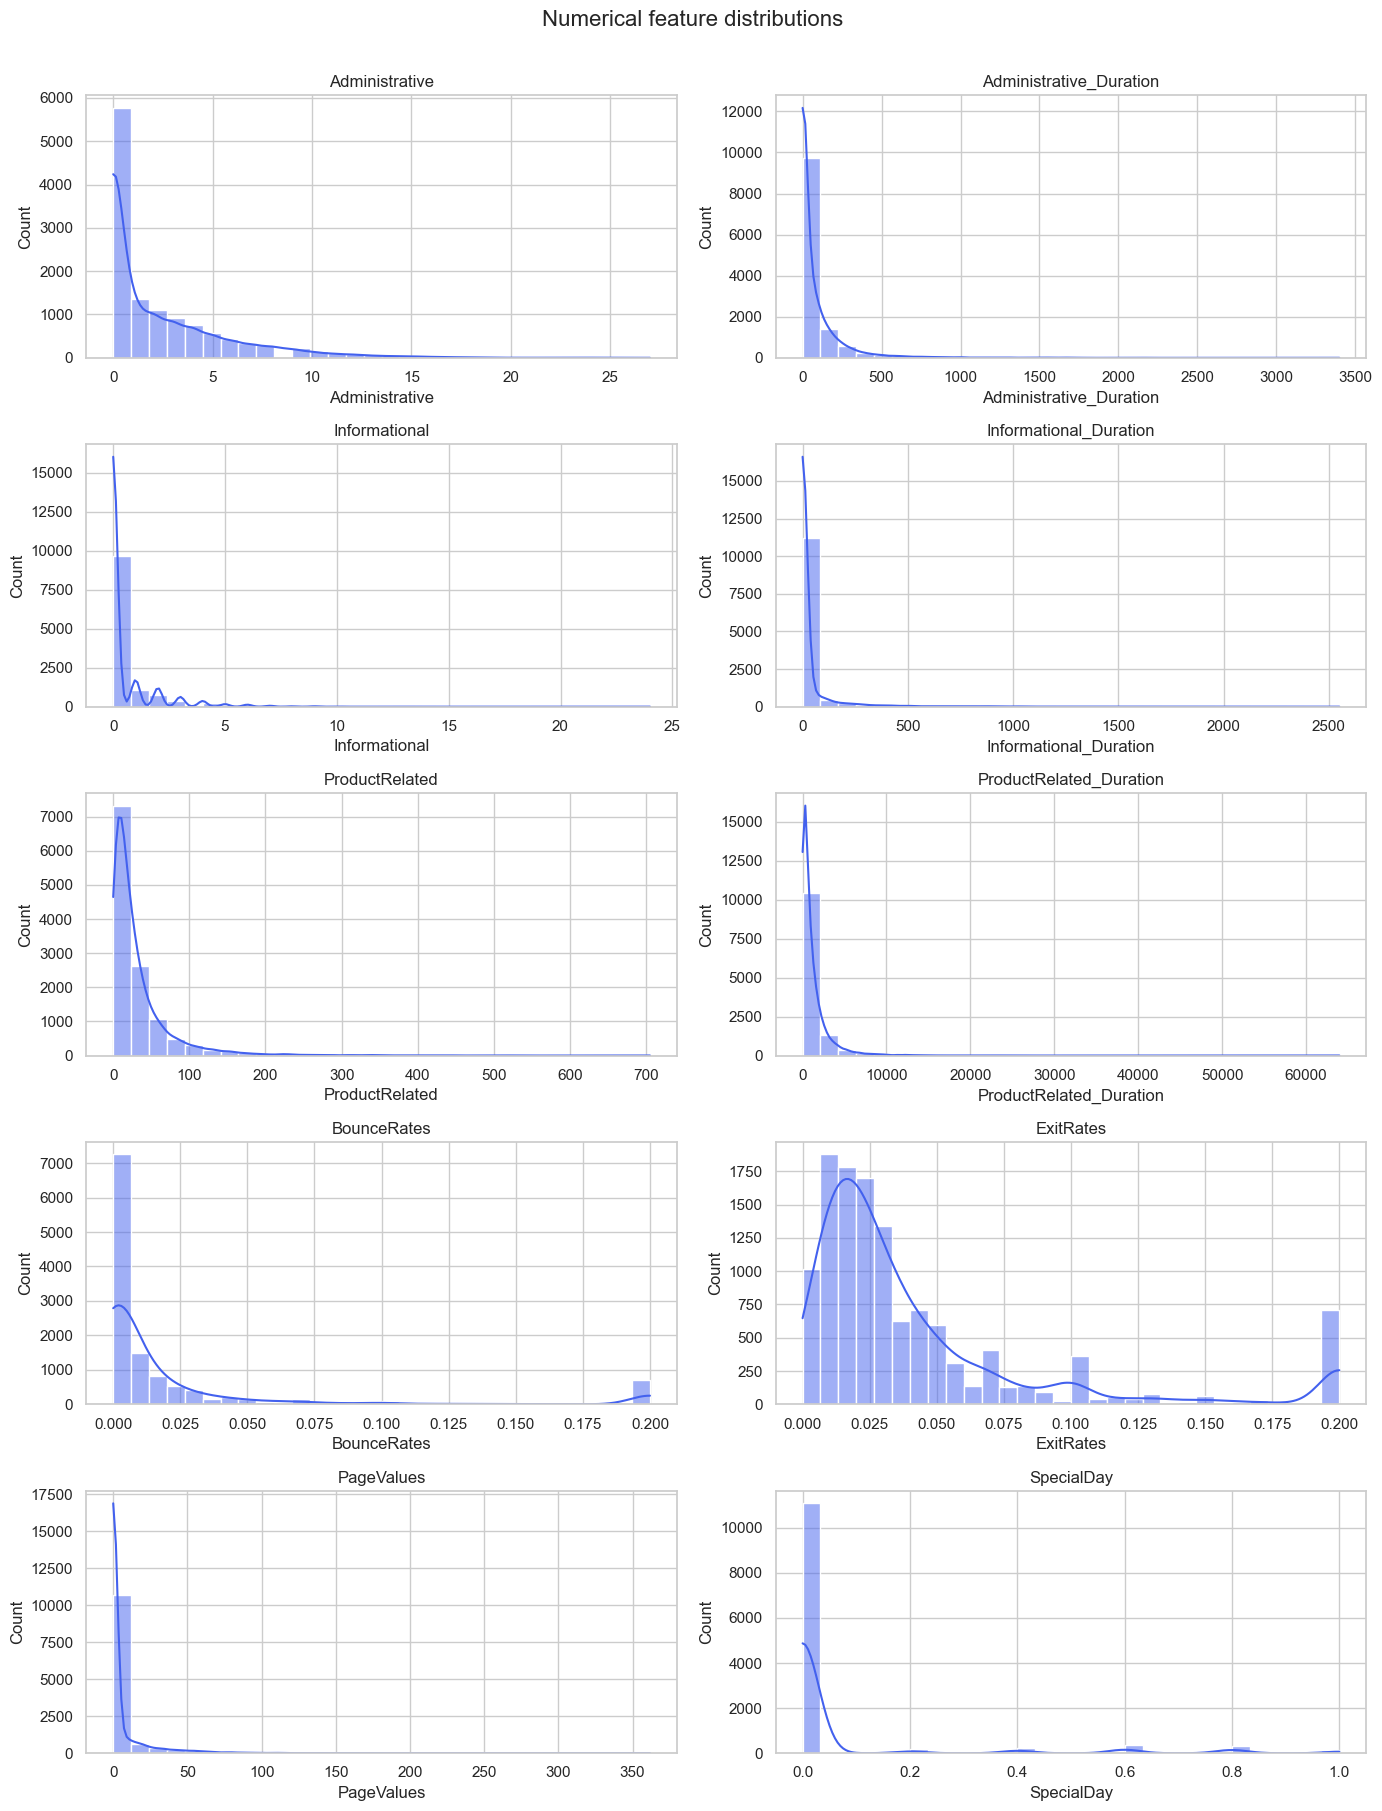

In [8]:
fig, axes = plt.subplots(5, 2, figsize=(14, 18))
for ax, column in zip(axes.flat, numerical_features):
    sns.histplot(X_eda[column], bins=30, kde=True, color="#4361ee", ax=ax)
    ax.set_title(column)
fig.suptitle("Numerical feature distributions", fontsize=16, y=1.005)
plt.tight_layout(); plt.show()

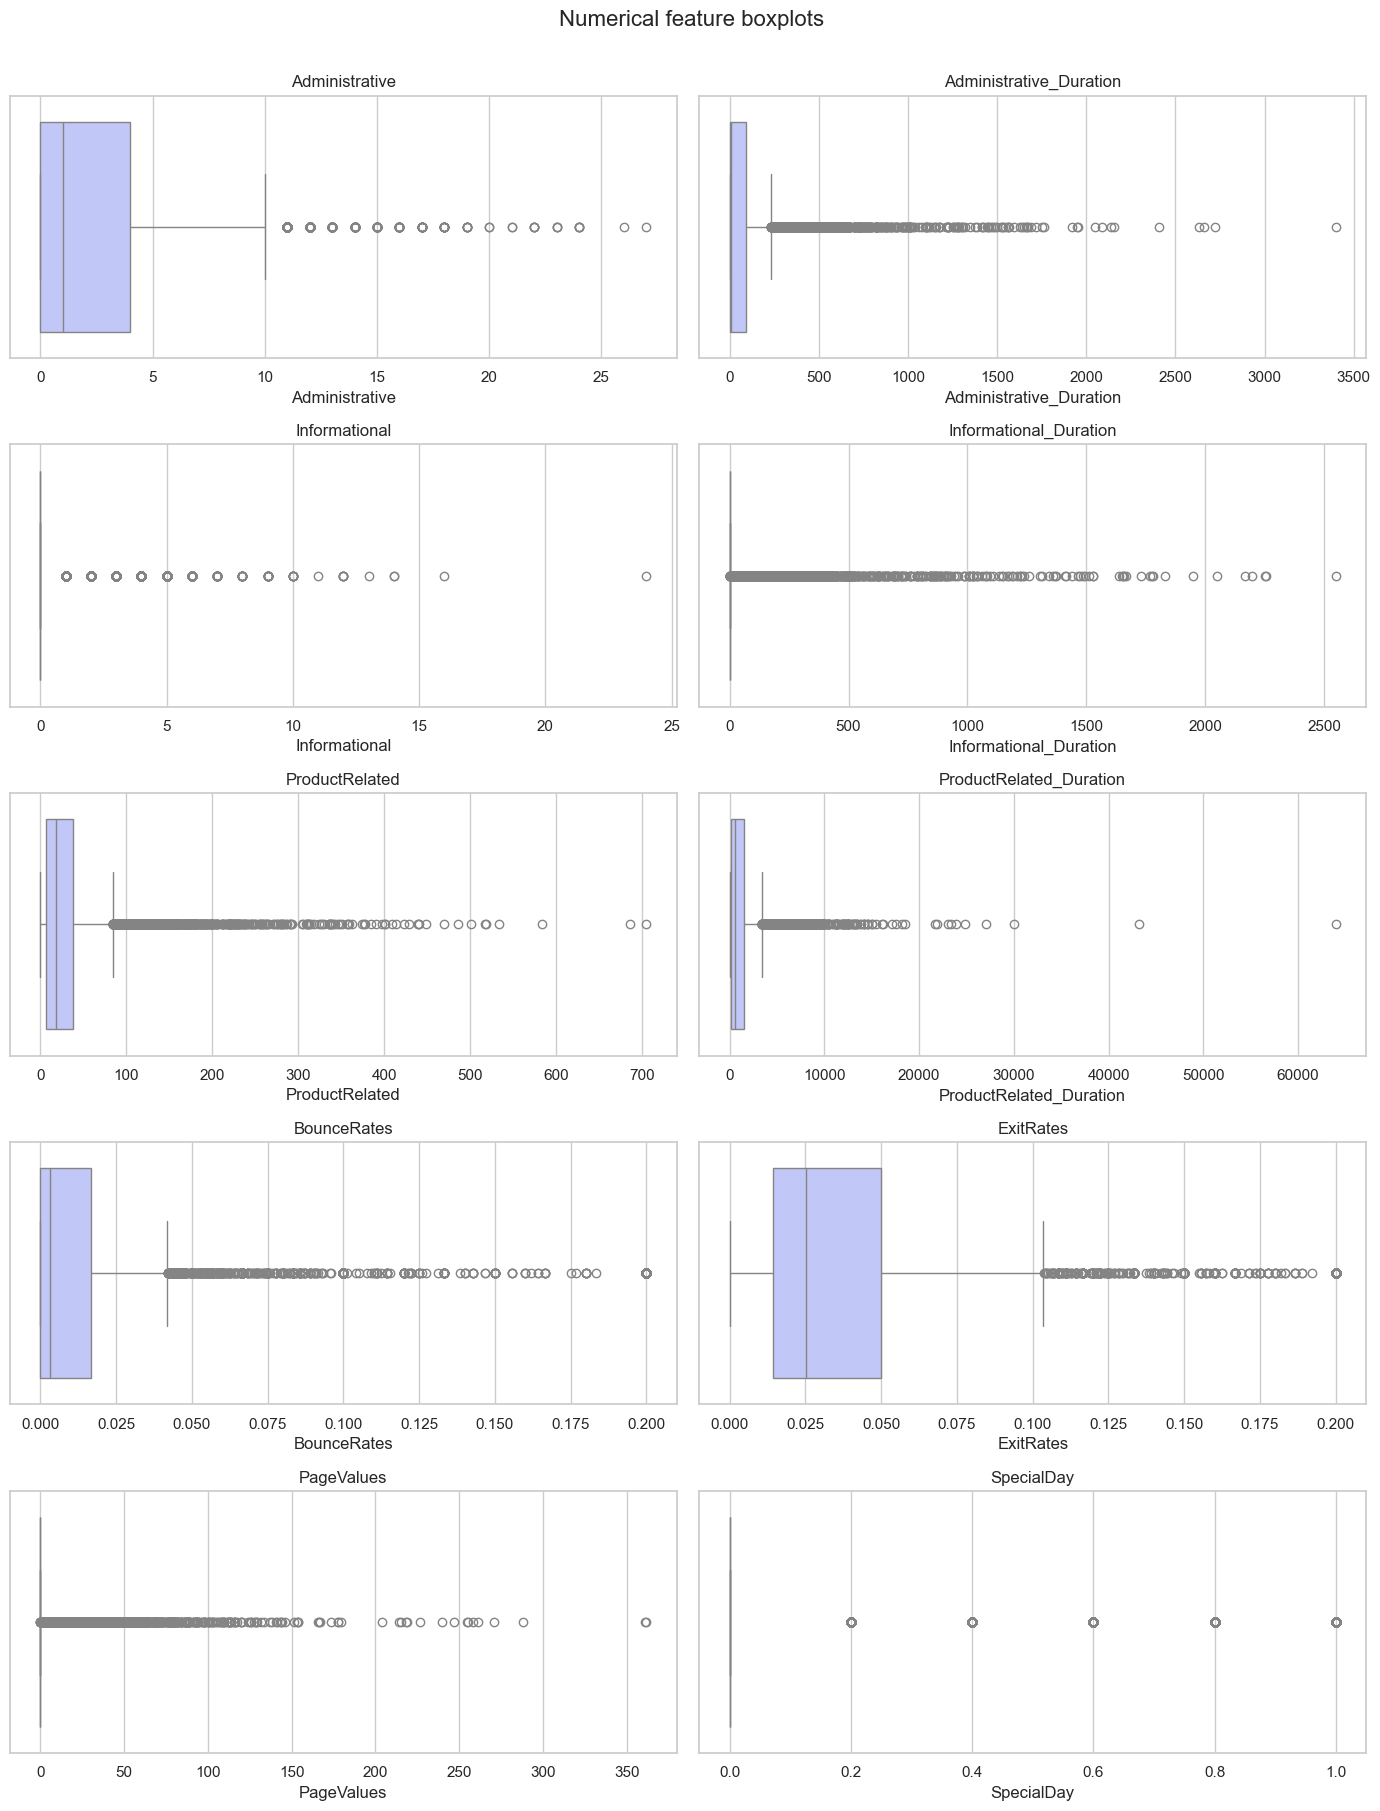

,Feature,IQR Flag Count,IQR Flag %
8,PageValues,2730,22.14
2,Informational,2631,21.34
3,Informational_Duration,2405,19.51
6,BounceRates,1551,12.58
9,SpecialDay,1251,10.15
1,Administrative_Duration,1172,9.51
7,ExitRates,1099,8.91
4,ProductRelated,987,8.00
5,ProductRelated_Duration,961,7.79
0,Administrative,404,3.28


IQR flags are not automatically erroneous records.


In [9]:
fig, axes = plt.subplots(5, 2, figsize=(14, 18))
for ax, column in zip(axes.flat, numerical_features):
    sns.boxplot(x=X_eda[column], color="#b8c0ff", ax=ax)
    ax.set_title(column)
fig.suptitle("Numerical feature boxplots", fontsize=16, y=1.005)
plt.tight_layout(); plt.show()

outlier_rows = []
for column in numerical_features:
    q1, q3 = X_eda[column].quantile([.25, .75]); iqr = q3 - q1
    flagged = ((X_eda[column] < q1 - 1.5*iqr) | (X_eda[column] > q3 + 1.5*iqr))
    outlier_rows.append({"Feature": column, "IQR Flag Count": int(flagged.sum()), "IQR Flag %": round(flagged.mean()*100, 2)})
outlier_summary = pd.DataFrame(outlier_rows).sort_values("IQR Flag Count", ascending=False)
display(outlier_summary)
print("IQR flags are not automatically erroneous records.")

,Count,Percentage
OperatingSystems,,
2,6601,53.54
1,2585,20.97
3,2555,20.72
4,478,3.88
8,79,0.64
6,19,0.15
7,7,0.06
5,6,0.05


,Count,Percentage
Browser,,
2,7961,64.57
1,2462,19.97
4,736,5.97
5,467,3.79
6,174,1.41
10,163,1.32
8,135,1.09
3,105,0.85
13,61,0.49


,Count,Percentage
Region,,
1,4780,38.77
3,2403,19.49
4,1182,9.59
2,1136,9.21
6,805,6.53
7,761,6.17
9,511,4.14
8,434,3.52
5,318,2.58


,Count,Percentage
TrafficType,,
2,3913,31.74
1,2451,19.88
3,2052,16.64
4,1069,8.67
13,738,5.99
10,450,3.65
6,444,3.60
8,343,2.78
5,260,2.11


,Count,Percentage
VisitorType,,
Returning_Visitor,10551,85.57
New_Visitor,1694,13.74
Other,85,0.69


,Count,Percentage
Month,,
May,3364,27.28
Nov,2998,24.31
Mar,1907,15.47
Dec,1727,14.01
Oct,549,4.45
Sep,448,3.63
Aug,433,3.51
Jul,432,3.50
June,288,2.34


,Count,Percentage
Weekend,,
False,9462,76.74
True,2868,23.26


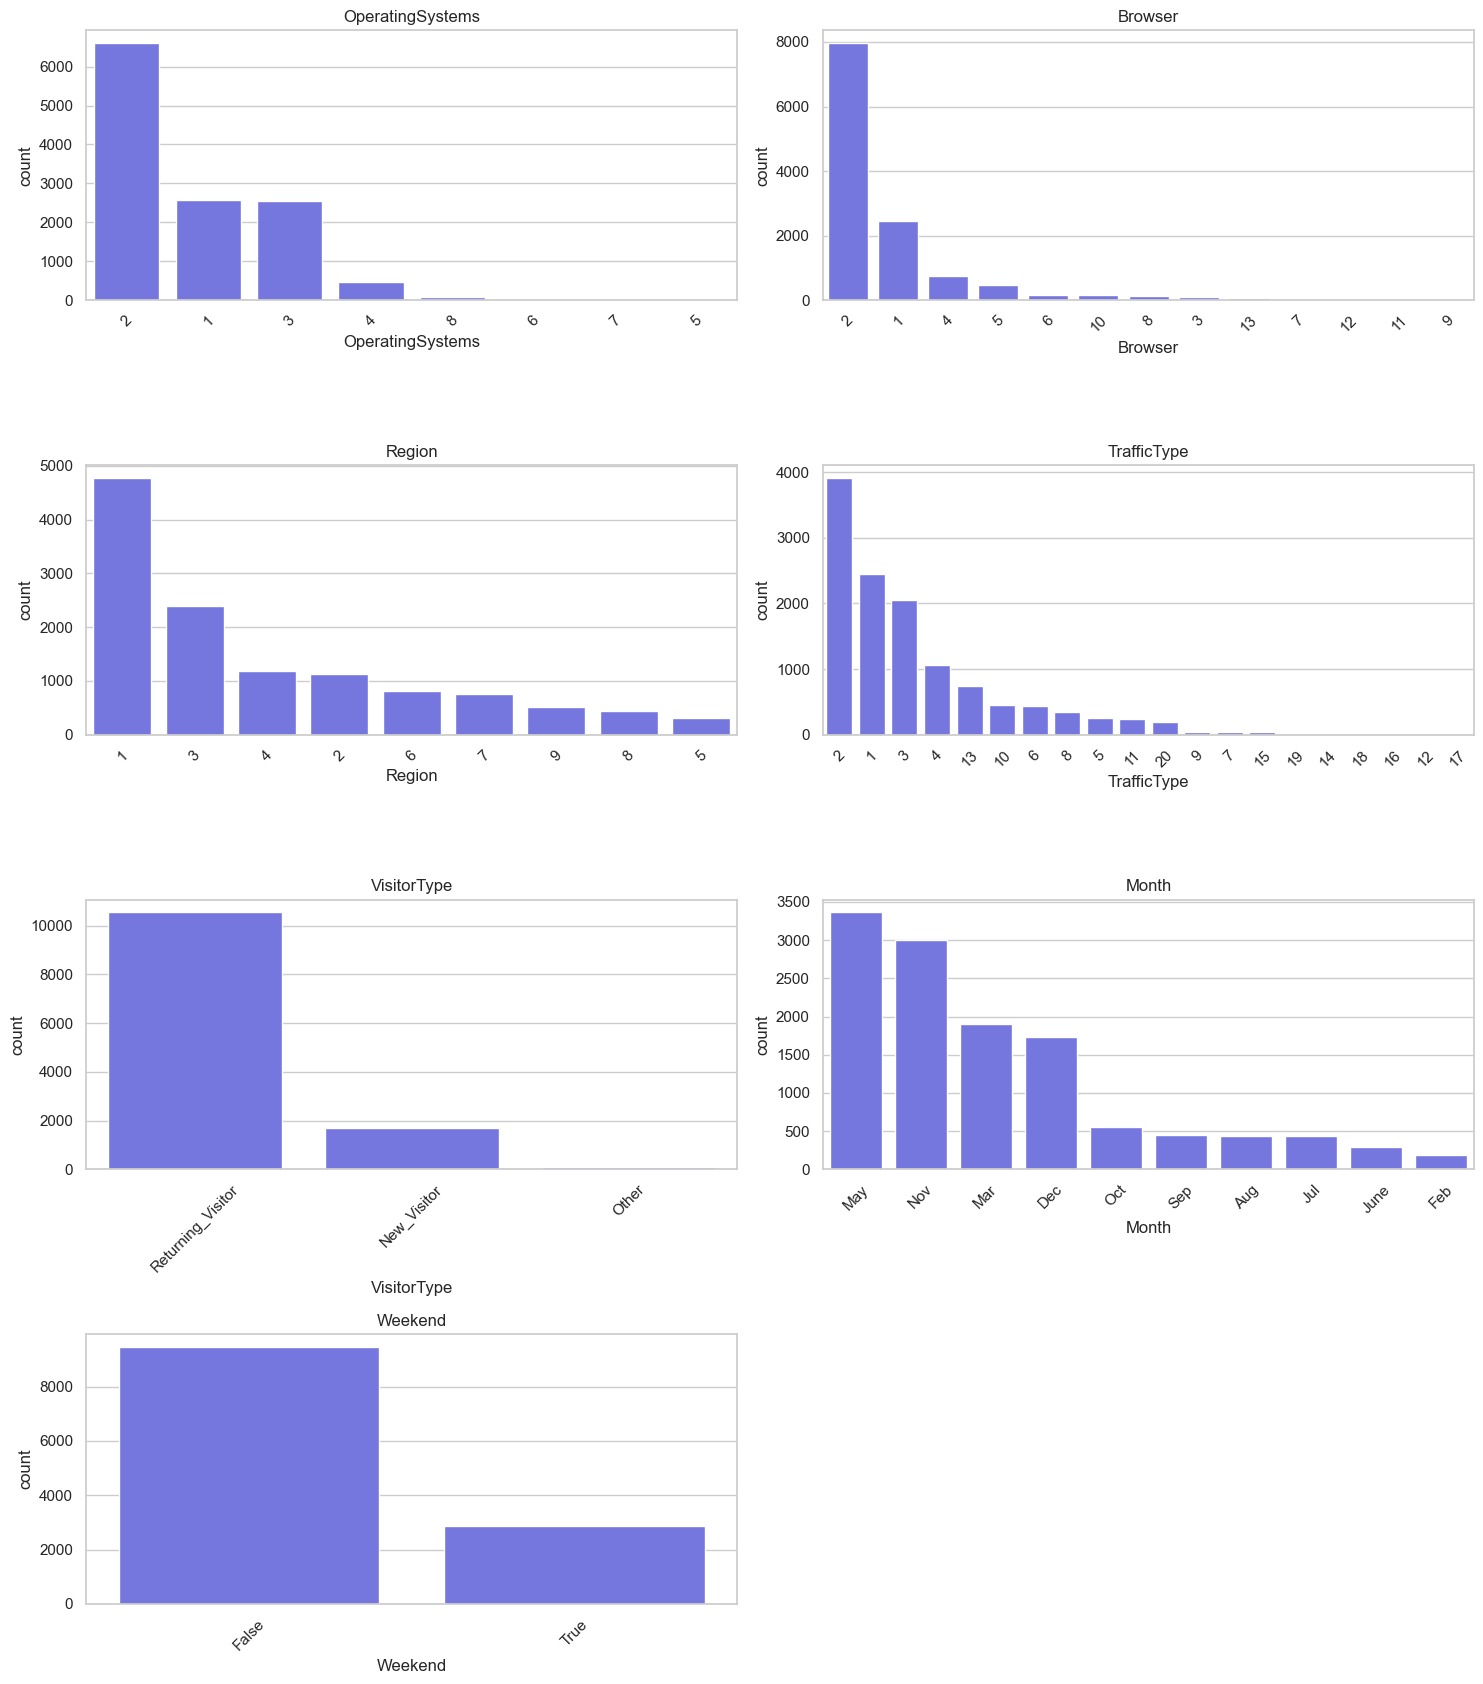

In [10]:
for column in categorical_features:
    counts_col = X_eda[column].value_counts(dropna=False)
    display(pd.DataFrame({"Count": counts_col, "Percentage": (counts_col / len(X_eda) * 100).round(2)}).rename_axis(column))

fig, axes = plt.subplots(4, 2, figsize=(15, 17))
for ax, column in zip(axes.flat, categorical_features):
    order = X_eda[column].value_counts().index
    sns.countplot(data=X_eda, x=column, order=order, color="#6366f1", ax=ax)
    ax.tick_params(axis="x", rotation=45)
    ax.set_title(column)
for ax in list(axes.flat)[len(categorical_features):]:
    fig.delaxes(ax)
plt.tight_layout(); plt.show()

## 5. Bivariate analysis — predictors versus purchase

These comparisons are **descriptive associations**, not proof of causality. We compare numerical features by target class and calculate category-level purchase rates.


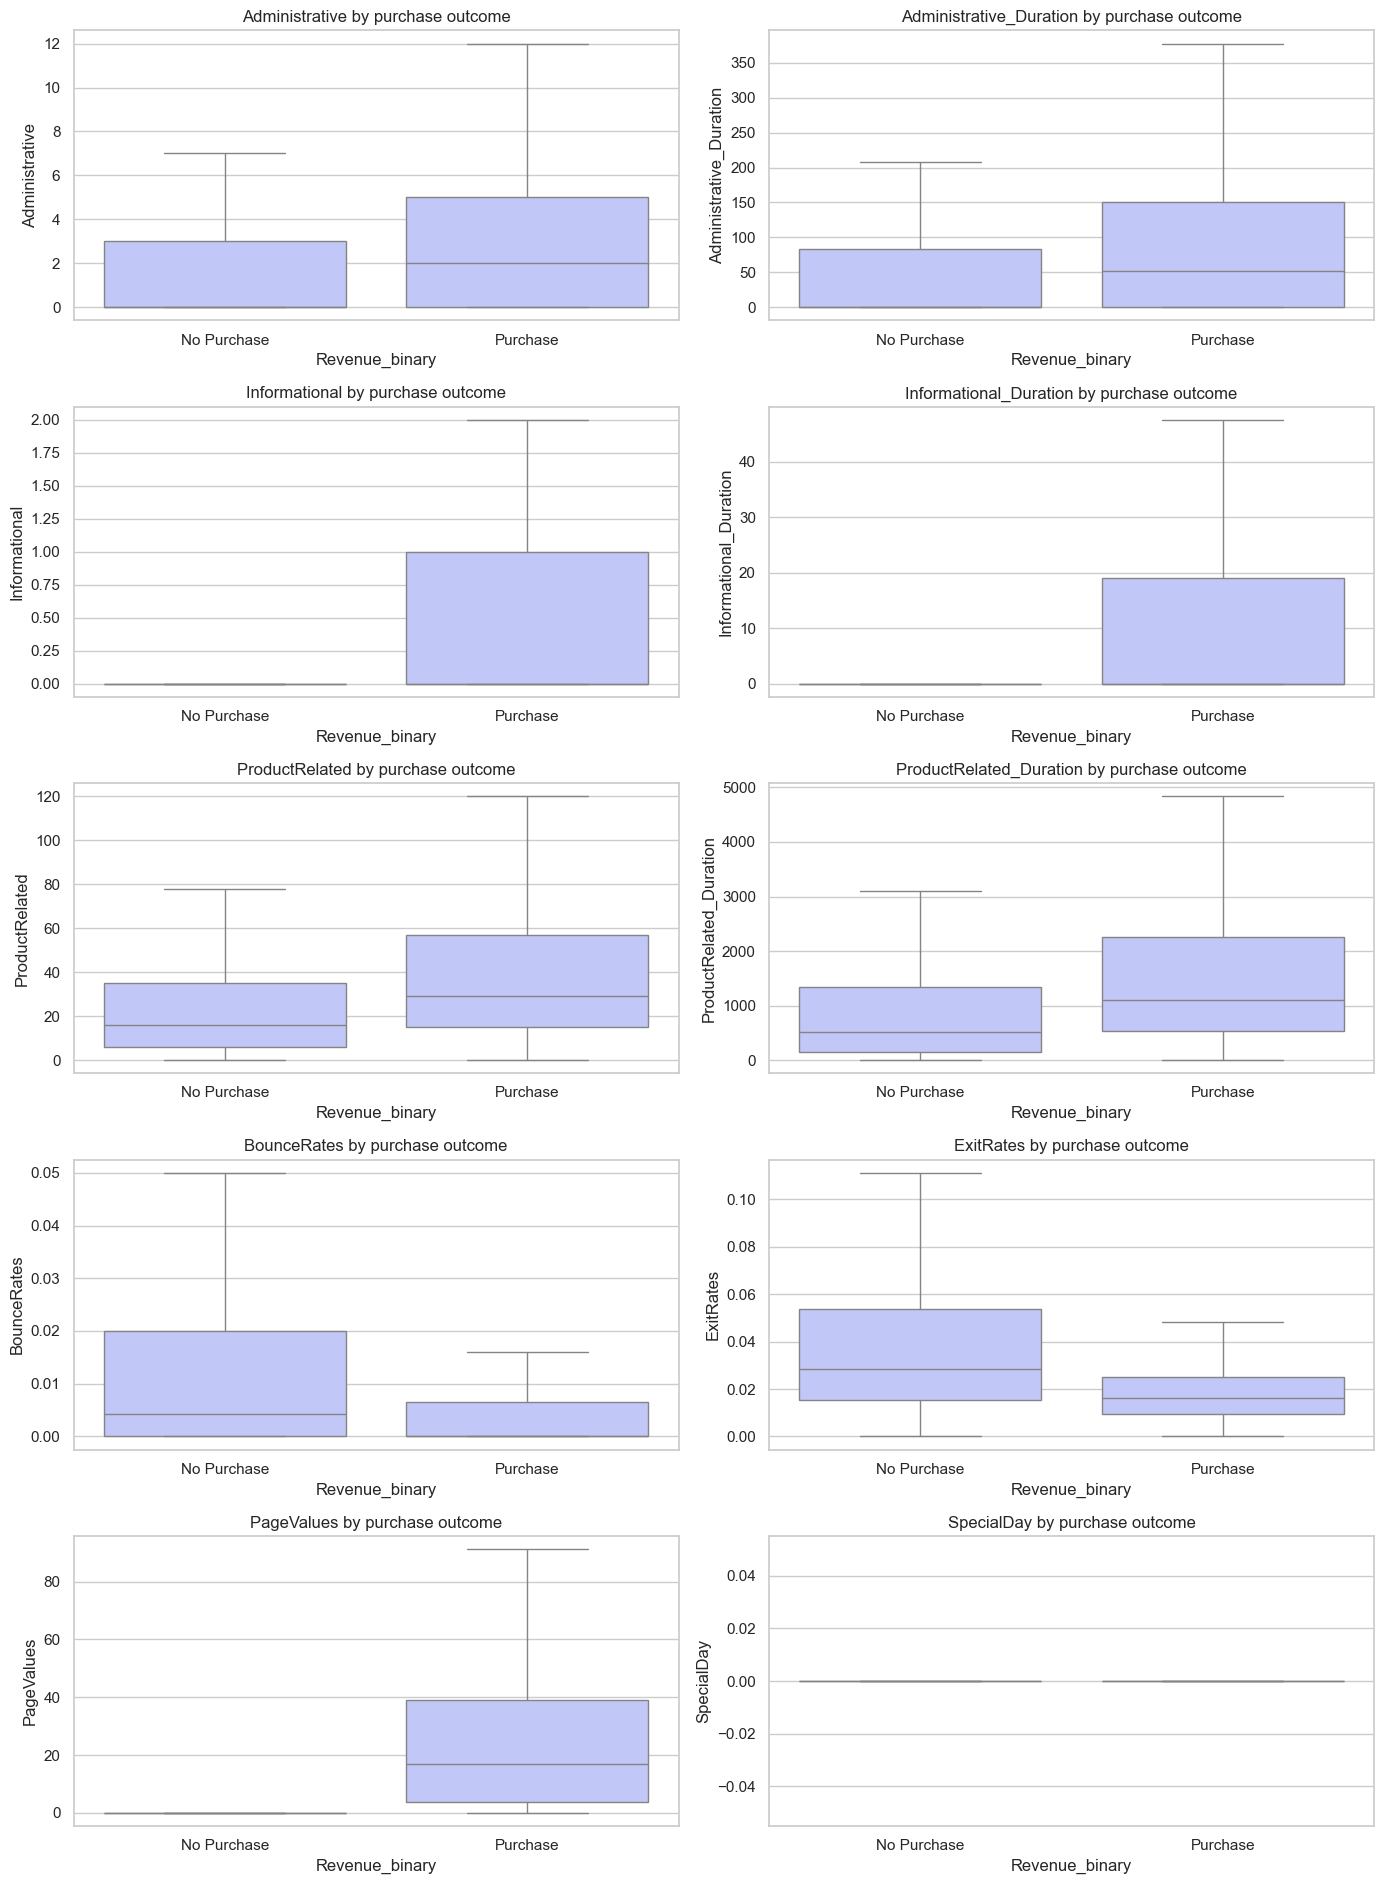

,No Purchase Median,Purchase Median
Administrative,0.000,2.000
Administrative_Duration,0.000,52.367
Informational,0.000,0.000
Informational_Duration,0.000,0.000
ProductRelated,16.000,29.000
ProductRelated_Duration,510.190,1109.906
BounceRates,0.004,0.000
ExitRates,0.029,0.016
PageValues,0.000,16.758
SpecialDay,0.000,0.000


In [11]:
eda = X_eda.copy()
eda["Revenue_binary"] = y.to_numpy()
fig, axes = plt.subplots(5, 2, figsize=(14, 19))
for ax, column in zip(axes.flat, numerical_features):
    sns.boxplot(data=eda, x="Revenue_binary", y=column, showfliers=False, color="#b8c0ff", ax=ax)
    ax.set_xticks([0,1], labels=["No Purchase", "Purchase"])
    ax.set_title(f"{column} by purchase outcome")
plt.tight_layout(); plt.show()

numeric_by_target = eda.groupby("Revenue_binary")[numerical_features].median().T
numeric_by_target.columns = ["No Purchase Median", "Purchase Median"]
display(numeric_by_target.round(3))


OperatingSystems: purchase rate by category


,Sessions,Purchase Rate %
OperatingSystems,,
2,6601,17.50
1,2585,14.66
3,2555,10.49
4,478,17.78
8,79,21.52
6,19,10.53
7,7,14.29
5,6,16.67



Browser: purchase rate by category


,Sessions,Purchase Rate %
Browser,,
2,7961,15.36
1,2462,14.83
4,736,17.66
5,467,18.42
6,174,11.49
10,163,19.63
8,135,15.56
3,105,4.76
13,61,26.23



Region: purchase rate by category


,Sessions,Purchase Rate %
Region,,
1,4780,16.13
3,2403,14.52
4,1182,14.81
2,1136,16.55
6,805,13.91
7,761,15.64
9,511,16.83
8,434,12.90
5,318,16.35


... (4 outputs left out)


Month: purchase rate by category


,Sessions,Purchase Rate %
Month,,
May,3364,10.85
Nov,2998,25.35
Mar,1907,10.07
Dec,1727,12.51
Oct,549,20.95
Sep,448,19.20
Aug,433,17.55
Jul,432,15.28
June,288,10.07



Weekend: purchase rate by category


,Sessions,Purchase Rate %
Weekend,,
False,9462,14.89
True,2868,17.40


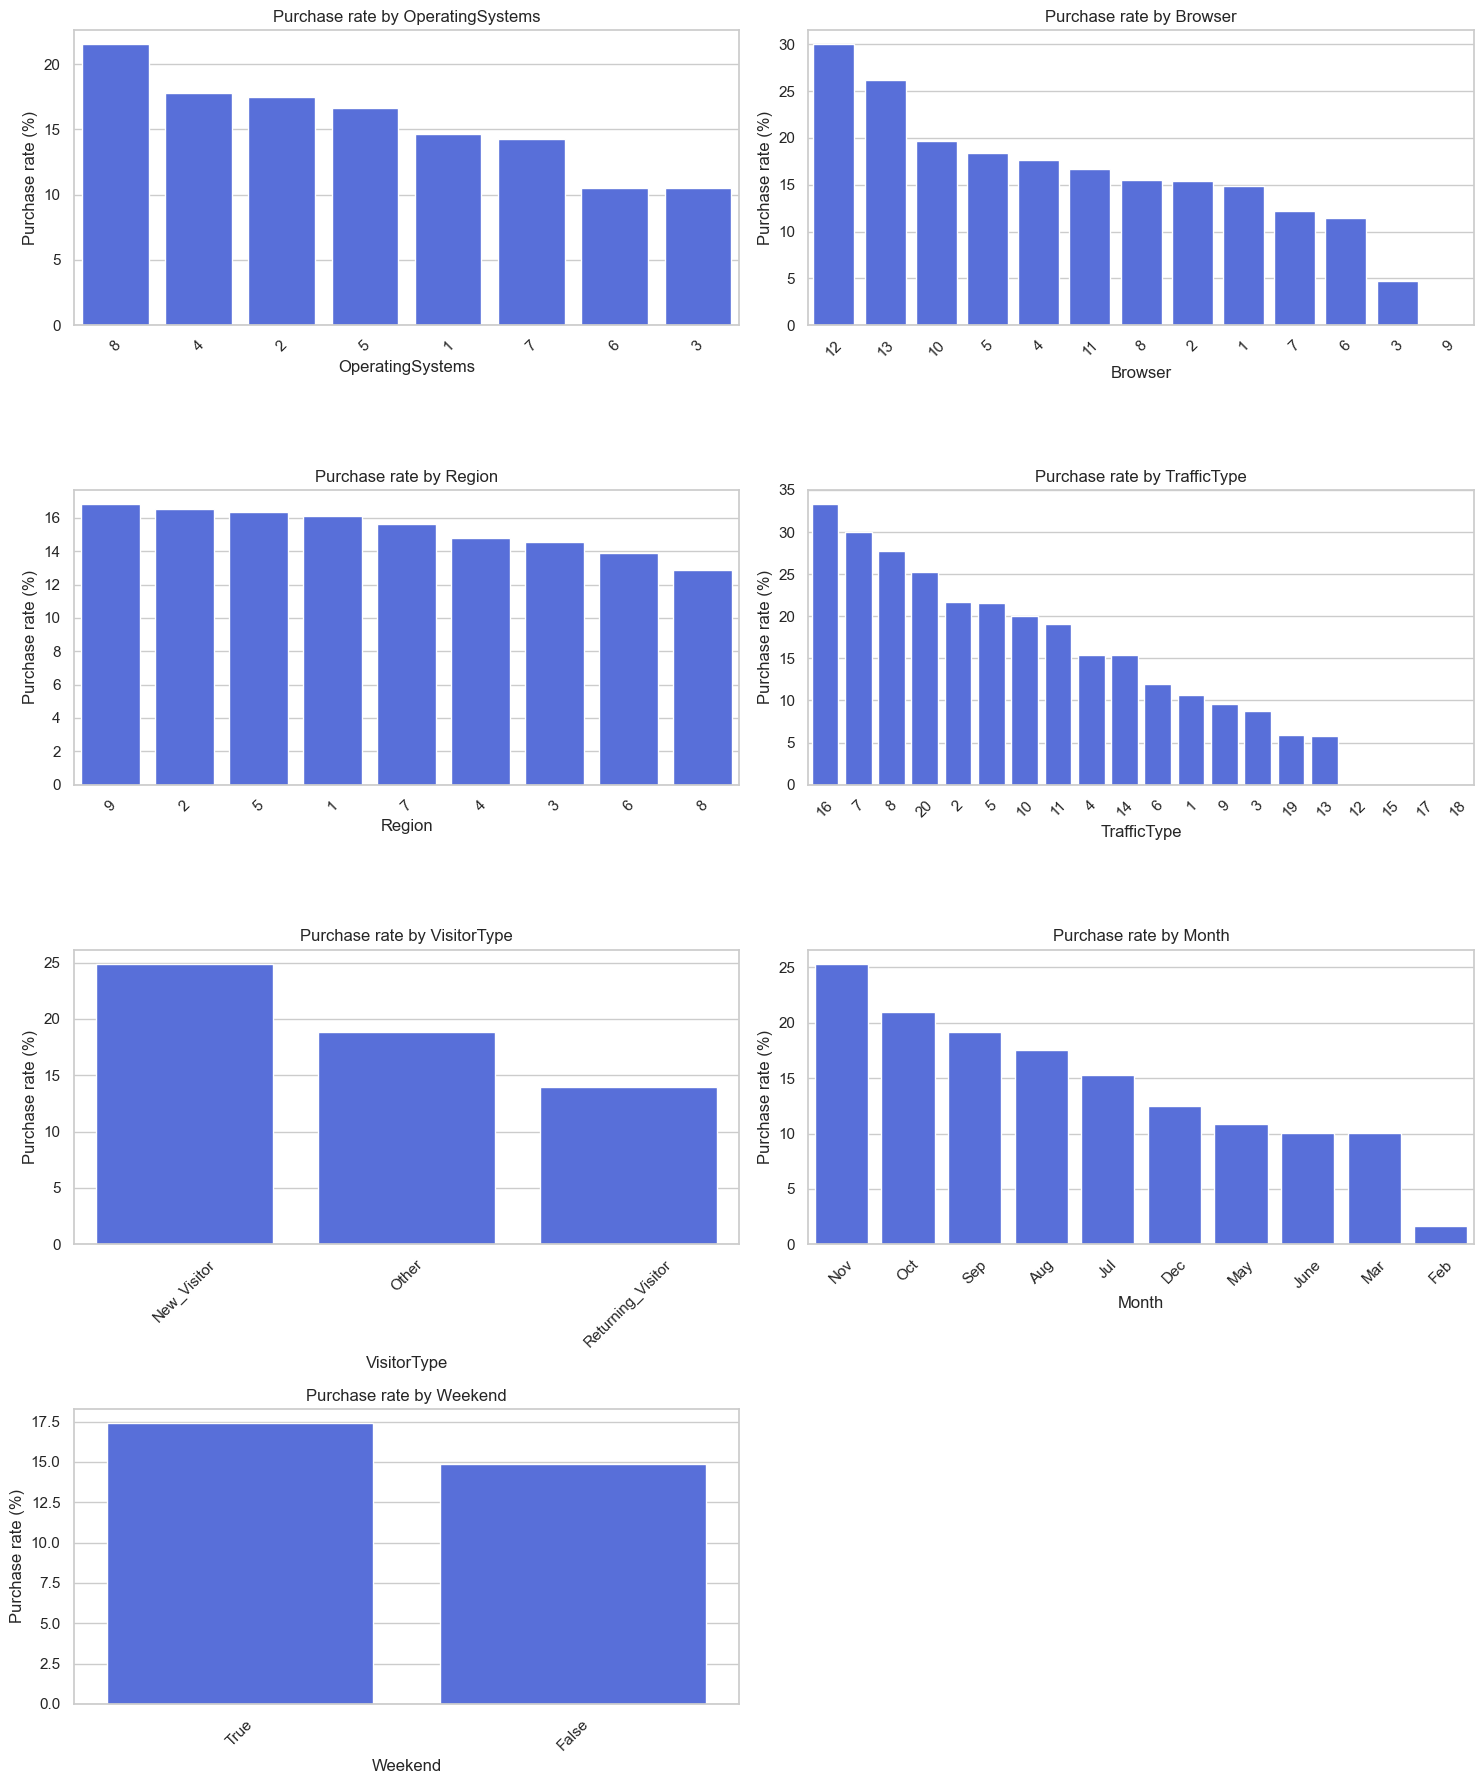

Caution: small categories may have unstable purchase-rate estimates.


In [12]:
for column in categorical_features:
    grouped = eda.groupby(column, dropna=False)["Revenue_binary"].agg(["size", "mean"])
    grouped.columns = ["Sessions", "Purchase Rate"]
    grouped["Purchase Rate %"] = (grouped["Purchase Rate"] * 100).round(2)
    print(f"\n{column}: purchase rate by category")
    display(grouped[["Sessions", "Purchase Rate %"]].sort_values("Sessions", ascending=False))

fig, axes = plt.subplots(4, 2, figsize=(15, 18))
for ax, column in zip(axes.flat, categorical_features):
    rates = eda.groupby(column)["Revenue_binary"].mean().sort_values(ascending=False)
    sns.barplot(x=rates.index.astype(str), y=rates.values * 100, color="#4361ee", ax=ax)
    ax.set(title=f"Purchase rate by {column}", ylabel="Purchase rate (%)", xlabel=column)
    ax.tick_params(axis="x", rotation=45)
for ax in list(axes.flat)[len(categorical_features):]:
    fig.delaxes(ax)
plt.tight_layout(); plt.show()
print("Caution: small categories may have unstable purchase-rate estimates.")

## 6. Correlation analysis

Pearson correlation is appropriate for exploring linear relationships among numeric variables. It does **not** measure all nonlinear associations. We deliberately exclude categorical integer codes from this heatmap.


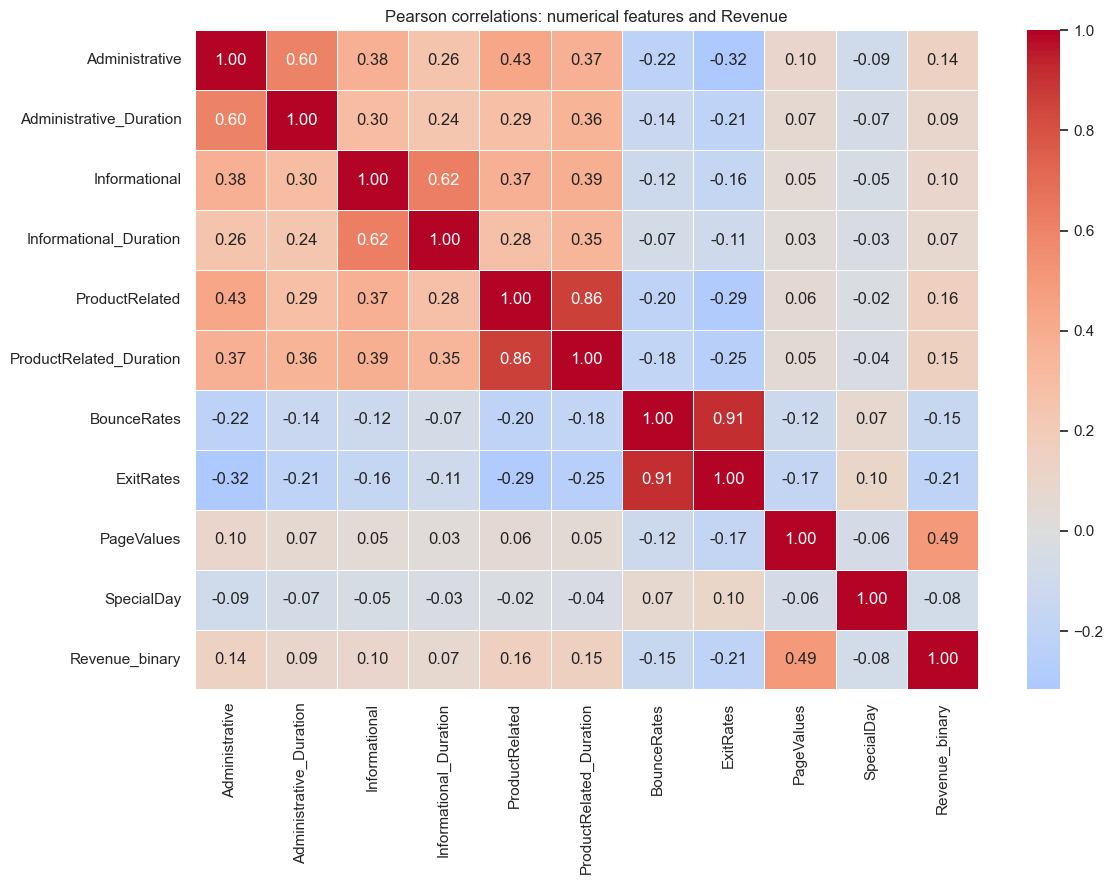

Numerical correlations with purchase outcome (ranked by absolute value):


,Pearson r
PageValues,0.493
ExitRates,-0.207
ProductRelated,0.159
ProductRelated_Duration,0.152
BounceRates,-0.151
Administrative,0.139
Informational,0.095
Administrative_Duration,0.094
SpecialDay,-0.082
Informational_Duration,0.070


In [13]:
correlation_df = eda[numerical_features + ["Revenue_binary"]].corr(method="pearson")
plt.figure(figsize=(12, 9))
sns.heatmap(correlation_df, annot=True, fmt=".2f", cmap="coolwarm", center=0, linewidths=.4)
plt.title("Pearson correlations: numerical features and Revenue")
plt.tight_layout(); plt.show()

revenue_corr = correlation_df["Revenue_binary"].drop("Revenue_binary").sort_values(key=abs, ascending=False)
print("Numerical correlations with purchase outcome (ranked by absolute value):")
display(revenue_corr.to_frame("Pearson r").round(3))

## 7. EDA findings and preprocessing plan

Fill in the following interpretation after running the cells. Your actual output takes precedence over published reference statistics.

- **Data quality:** Record missing-value, duplicate-row, and conflicting-label counts. Do not claim zero duplicates unless your actual local CSV confirms it.
- **Class imbalance:** Compare your purchase share against the original ~15.47%. Accuracy alone can be misleading.
- **Numerical distributions:** Identify strongly skewed features and potential outliers. Avoid automatic deletion.
- **Categorical predictors:** Use appropriate encoding (for example, one-hot encoding) for integer-coded categories as well as text categories.
- **Scaling:** KNN, SVM, and Logistic Regression typically benefit from scaled numerical features.
- **Leakage prevention:** Split into training/test data before fitting any imputers, encoders, or scalers; use `Pipeline`/`ColumnTransformer` fitted only on training data.
- **Model comparison:** Use the same held-out test set for Logistic Regression, Decision Tree, KNN, Gaussian Naive Bayes, and SVM. Report Accuracy, AUC, Precision, Recall, F1, and MCC. Use probability or decision scores for AUC.
- **Streamlit:** Save fitted model pipelines; evaluate uploaded labeled test CSVs without retraining.


## 8. Optional preview: stratified train/test split (no model training)

The following cell demonstrates preserving class proportions. In the actual modeling step, make the split once and persist the held-out test CSV. Do not use the held-out test set to tune preprocessing or models.


In [14]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X_eda, y, test_size=0.20, random_state=42, stratify=y
)
print("Train shape:", X_train.shape, "Test shape:", X_test.shape)
print("Train purchase %:", round(y_train.mean()*100, 2))
print("Test purchase %:", round(y_test.mean()*100, 2))
print("Preview only — no model fitted and no CSV written.")

Train shape: (9864, 17) Test shape: (2466, 17)
Train purchase %: 15.47
Test purchase %: 15.49
Preview only — no model fitted and no CSV written.
